In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv('flipkart_products.csv')

In [3]:
df.sample(5)

,Product Name,Price,Discription,Rating,Page Number
531,"LYF F8 (Blue, 8 GB)","₹5,199",1 GB RAM | 8 GB ROM | Expandable Upto 128 GB11...,3.6,23
264,"IQOO 15 5G (Legend, 256 GB)","₹76,740",12 GB RAM | 256 GB ROM17.4 cm (6.85 inch) Disp...,4.7,12
793,"REDMI Note-14 Pro 5G (Ivy Green, 256 GB)","₹27,374",8 GB RAM | 256 GB ROM16.94 cm (6.67 inch) Disp...,4.3,34
145,"realme Narzo 100 Lite 5G (Thunder Black, 64 GB)","₹16,848",4 GB RAM | 64 GB ROM17.27 cm (6.8 inch) Displa...,4.2,7
315,"POCO C81 (Sunset Gold, 64 GB)","₹12,999",4 GB RAM | 64 GB ROM | Expandable Upto 2 TB17....,3.7,14


In [4]:
df.shape

(984, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product Name  984 non-null    object 
 1   Price         975 non-null    object 
 2   Discription   983 non-null    object 
 3   Rating        921 non-null    float64
 4   Page Number   984 non-null    int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 38.6+ KB


# Data Cleaning and Feature Extraction

In [6]:
# Changing the datatype of Price column from object to float after removing the ₹ symbol and commas

df['Price'] = df['Price'].astype(str).str.replace('₹', '').str.replace(',', '').astype(float)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product Name  984 non-null    object 
 1   Price         975 non-null    float64
 2   Discription   983 non-null    object 
 3   Rating        921 non-null    float64
 4   Page Number   984 non-null    int64  
dtypes: float64(2), int64(1), object(2)
memory usage: 38.6+ KB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,975.0,24418.155897,23311.686516,106.0,8995.0,17999.0,33248.5,189999.0
Rating,921.0,4.150489,0.359048,2.3,4.1,4.2,4.4,5.0
Page Number,984.0,21.000000,11.838176,1.0,11.0,21.0,31.0,41.0


In [9]:
# Permanently removes all rows where Price is less than 999

df[df['Price'] < 999].sort_values(by='Price', ascending=False).head(10)
df = df[df['Price'] >= 999]

In [10]:
df.sample(5)

,Product Name,Price,Discription,Rating,Page Number
308,"POCO C71 (Cool Blue, 64 GB)",8999.0,4 GB RAM | 64 GB ROM | Expandable Upto 2 TB17....,3.8,13
162,"MOTOROLA g37 (PANTONE Nautical Blue, 64 GB)",17249.0,4 GB RAM | 64 GB ROM | Expandable Upto 1 TB16....,4.3,7
652,"REDMI Note 15 5G (Glacier Blue, 256 GB)",34899.0,8 GB RAM | 256 GB ROM17.2 cm (6.77 inch) Displ...,4.4,28
459,"itel A300C (SILVER MIST, 64 GB)",10999.0,4 GB RAM | 64 GB ROM | Expandable Upto 1 TB16....,NaN,20
571,"oneme m 17 (METALIC GOLD, 16 GB)",6400.0,2 GB RAM | 16 GB ROM7.62 cm (3 inch) HD Displa...,NaN,24


In [11]:
df.isnull().sum()

Product Name     0
Price            0
Discription      0
Rating          27
Page Number      0
dtype: int64

In [12]:
missing_prices = df[df['Price'].isnull()]
missing_prices

,Product Name,Price,Discription,Rating,Page Number


In [13]:
ram = df['Discription'].str.extract(r'(\d+(?:\.\d+)?)\s*([MGT]B)\s*RAM', flags=re.IGNORECASE)
rom = df['Discription'].str.extract(r'(\d+(?:\.\d+)?)\s*([MGT]B)\s*ROM', flags=re.IGNORECASE)

to_gb = {'MB': 1/1024, 'GB': 1, 'TB': 1024}

df['RAM_GB'] = ram[0].astype(float) * ram[1].str.upper().map(to_gb)
df['ROM_GB'] = rom[0].astype(float) * rom[1].str.upper().map(to_gb)

In [14]:
df.shape

(938, 7)

In [15]:
df = df.drop_duplicates().reset_index(drop=True)    
df = df.rename(columns={'Discription': 'Description'})

In [16]:
df.shape

(937, 7)

In [17]:
df.sample(5)

,Product Name,Price,Description,Rating,Page Number,RAM_GB,ROM_GB
202,"realme Narzo 100x 5g (Midnight Black, 128 GB)",22999.0,6 GB RAM | 128 GB ROM17.3 cm (6.81 inch) HD+ D...,4.2,9,6.0,128.0
848,"MOTOROLA Edge 70 Fusion (Pantone COUNTRY AIR, ...",36999.0,12 GB RAM | 512 GB ROM17.27 cm (6.8 inch) Supe...,4.3,38,12.0,512.0
456,"SIAVANTAGE PRO 25 (Blue, 32 GB)",5999.0,3 GB RAM | 32 GB ROM16.0 cm (6.3 inch) Display...,2.7,20,3.0,32.0
765,"realme 16 Pro 5G (Pebble Grey, 256 GB)",46999.0,8 GB RAM | 256 GB ROM17.22 cm (6.78 inch) Full...,4.3,34,8.0,256.0
50,"Tecno Spark Go 3 (Titanium Grey, 64 GB)",12499.0,4 GB RAM | 64 GB ROM17.12 cm (6.74 inch) HD+ D...,4.1,3,4.0,64.0


In [18]:
df[df['RAM_GB'].isna()]

,Product Name,Price,Description,Rating,Page Number,RAM_GB,ROM_GB
215,"Apple iPhone 16 Plus (White, 128 GB)",79900.0,128 GB ROM17.02 cm (6.7 inch) Super Retina XDR...,4.6,10,NaN,128.0
287,"Apple iPhone 16 Plus (Ultramarine, 128 GB)",79900.0,128 GB ROM17.02 cm (6.7 inch) Super Retina XDR...,4.6,13,NaN,128.0
595,"Apple iPhone 16e (White, 256 GB)",69900.0,256 GB ROM15.49 cm (6.1 inch) Super Retina XDR...,4.5,27,NaN,256.0
609,"Apple iPhone 16e (White, 256 GB)",69900.0,256 GB ROM15.49 cm (6.1 inch) Super Retina XDR...,4.5,28,NaN,256.0
612,"Apple iPhone 16 (Teal, 128 GB)",69900.0,128 GB ROM15.49 cm (6.1 inch) Super Retina XDR...,4.6,28,NaN,128.0
708,"Apple iPhone 16e (Black, 128 GB)",59900.0,128 GB ROM15.49 cm (6.1 inch) Super Retina XDR...,4.5,32,NaN,128.0
800,"Apple iPhone 16 (Ultramarine, 128 GB)",69900.0,128 GB ROM15.49 cm (6.1 inch) Super Retina XDR...,4.6,36,NaN,128.0


In [19]:
df['Rating'] = df['Rating'].fillna(df['Rating'].median())


In [20]:
df.isnull().sum()

Product Name    0
Price           0
Description     0
Rating          0
Page Number     0
RAM_GB          7
ROM_GB          0
dtype: int64

# EDA

### Q1. How is the catalogue spread across price tiers, and what is the typical price?

In [21]:
print('Mean:', df['Price'].mean())
print('Median:', df['Price'].median())
print('Skewness:', df['Price'].skew())

Mean: 25383.201707577373
Median: 18999.0
Skewness: 2.5762388039221857


In [22]:
df['Price_Tier'] = pd.cut(df['Price'],
                          bins=[0, 10000, 20000, 30000, 50000, float('inf')],
                          labels=['<10k', '10-20k', '20-30k', '30-50k', '50k+'],
                          right=False)

counts = df['Price_Tier'].value_counts().sort_index()
share = (counts / len(df) * 100).round(1)
tier_table = pd.DataFrame({'listings': counts, 'share_%': share}).reset_index()
tier_table

,Price_Tier,listings,share_%
0,<10k,269,28.7
1,10-20k,228,24.3
2,20-30k,156,16.6
3,30-50k,201,21.5
4,50k+,83,8.9


In [23]:
print('Share of Price above 20k:', tier_table['share_%'][0] + tier_table['share_%'][1])

Share of Price above 20k: 53.0


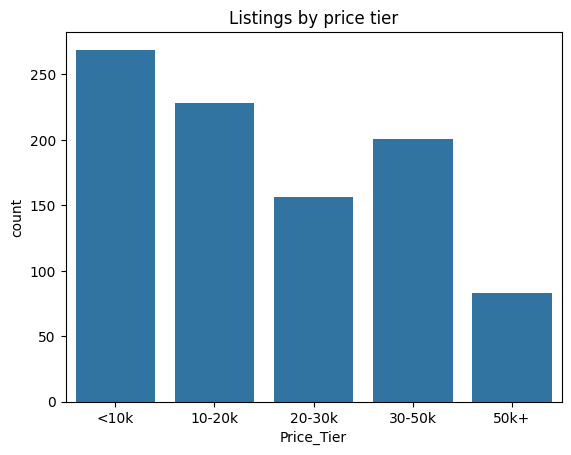

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Price_Tier', data=df)
plt.title('Listings by price tier')
plt.show()

#### The typical phone costs ₹18,999 (median). The mean is higher at ₹25,383 because a few flagships, up to ₹189,999, pull it up (skew 2.58). 53% of listings cost under ₹20k; the biggest tier is under ₹10k (28.7%) and only 8.9% cost ₹50k or more.

### ----------------------------------------------------------------------------------------------------------

### Q2. Which brands have the most products, and where do they sit on price?

In [25]:
df.head()

,Product Name,Price,Description,Rating,Page Number,RAM_GB,ROM_GB,Price_Tier
0,"Tecno Spark Go 3 (Titanium Grey, 64 GB)",12499.0,4 GB RAM | 64 GB ROM17.12 cm (6.74 inch) HD+ D...,4.1,1,4.0,64.0,10-20k
1,"Tecno Spark Go 3 (Ink Black, 64 GB)",12499.0,4 GB RAM | 64 GB ROM17.12 cm (6.74 inch) HD+ D...,4.1,1,4.0,64.0,10-20k
2,"Ai+ Pulse 2 (Blue, 64 GB)",10999.0,4 GB RAM | 64 GB ROM | Expandable Upto 1 TB17....,4.1,1,4.0,64.0,10-20k
3,"MOTOROLA g37 (PANTONE Nautical Blue, 64 GB)",17249.0,4 GB RAM | 64 GB ROM | Expandable Upto 1 TB16....,4.3,1,4.0,64.0,10-20k
4,"POCO C71 (Desert Gold, 64 GB)",8999.0,4 GB RAM | 64 GB ROM | Expandable Upto 2 TB17....,3.8,1,4.0,64.0,<10k


In [26]:
df["Brand"] = df["Product Name"].str.lower().str.split().str[0]
Top_10 = df['Brand'].value_counts().head(10).index
Top_10

Index(['realme', 'redmi', 'samsung', 'poco', 'vivo', 'motorola', 'itel',
       'tecno', 'infinix', 'oppo'],
      dtype='object', name='Brand')

In [27]:
# Grouping the data by Brand and calculating the number of listings, median, minimum, and maximum prices for the top 10 brands
brand_summary = (df[df["Brand"].isin(Top_10)]
                .groupby('Brand')['Price']
                .agg(listings="size", median="median", min="min", max="max")
                .sort_values("median"))
brand_summary

,listings,median,min,max
Brand,,,,
itel,55,6897.0,5595.0,12990.0
tecno,54,12499.0,12499.0,33999.0
infinix,53,13499.0,6699.0,40999.0
poco,66,13499.0,6810.0,52999.0
motorola,57,17249.0,6999.0,64999.0
redmi,81,21843.0,4499.0,49999.0
realme,107,30999.0,7249.0,78999.0
samsung,74,31722.0,6499.0,189999.0
vivo,60,37999.0,13999.0,119999.0


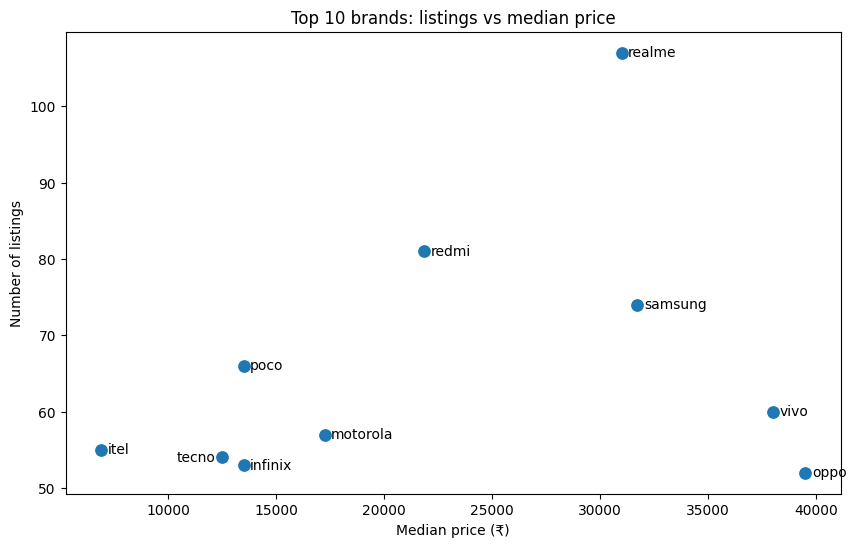

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(x="median", y="listings", data=brand_summary, s=100)

for brand, row in brand_summary.iterrows():
    if brand == "tecno":
        plt.text(row["median"] - 300, row["listings"], brand, ha="right", va="center")
    else:
        plt.text(row["median"] + 300, row["listings"], brand, va="center")

plt.title("Top 10 brands: listings vs median price")
plt.xlabel("Median price (₹)")
plt.ylabel("Number of listings")
plt.show()

#### realme, redmi, samsung, poco and vivo have the most listings, and across the top 10, itel is the cheapest (median ₹6,897) and oppo the most expensive (₹39,499).

### Q3. Do higher-priced phones get higher ratings?

In [29]:
df['Rating'].describe()

count    937.000000
mean       4.153575
std        0.353237
min        2.300000
25%        4.100000
50%        4.200000
75%        4.400000
max        5.000000
Name: Rating, dtype: float64

In [30]:
df.sample(5)

,Product Name,Price,Description,Rating,Page Number,RAM_GB,ROM_GB,Price_Tier,Brand
544,REDMI A5 - Locked with Airtel Prepaid (Pondic...,8995.0,3 GB RAM | 64 GB ROM | Expandable Upto 2 TB17....,4.1,25,3.0,64.0,<10k,redmi
185,"OnePlus Nord 6 (Quick Silver, 256 GB)",46740.0,8 GB RAM | 256 GB ROM | Expandable Upto 256 GB...,4.5,8,8.0,256.0,30-50k,oneplus
709,"POCO F6 5G (Titanium, 256 GB)",31999.0,12 GB RAM | 256 GB ROM16.94 cm (6.67 inch) Dis...,4.3,32,12.0,256.0,30-50k,poco
616,"realme 16 5G (Air White, 256 GB)",49999.0,12 GB RAM | 256 GB ROM16.69 cm (6.57 inch) Ful...,4.3,28,12.0,256.0,30-50k,realme
450,"itel A60 (VertMenthe, 32 GB)",5999.0,2 GB RAM | 32 GB ROM16.76 cm (6.6 inch) HD Dis...,4.1,20,2.0,32.0,<10k,itel


In [31]:
rating_by_tier = df.groupby('Price_Tier', observed=False)['Rating'].agg(['count', 'mean', 'median', 'std']).round(2)
rating_by_tier

,count,mean,median,std
Price_Tier,,,,
<10k,269,3.89,4.1,0.41
10-20k,228,4.04,4.1,0.29
20-30k,156,4.28,4.3,0.14
30-50k,201,4.37,4.4,0.14
50k+,83,4.55,4.6,0.11


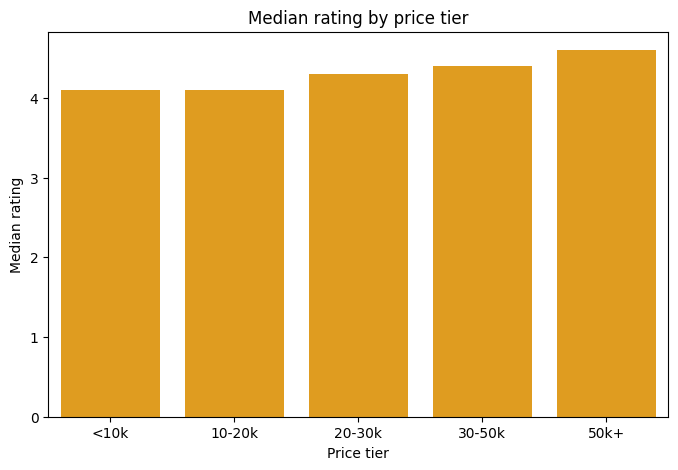

In [32]:
plt.style.use('default')   # black background, white text and axes

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=rating_by_tier.reset_index(), x='Price_Tier', y='median',
            color='orange', ax=ax)
ax.set_title('Median rating by price tier')
ax.set_xlabel('Price tier')
ax.set_ylabel('Median rating')
plt.show()

#### Yes, higher-priced phones rate higher, with median rating rising from 4.1 (<10k) to 4.6 (50k+).

### Q4. Which brands rate best within the same price tier?

In [33]:
df['Brand'].describe()

count        937
unique        42
top       realme
freq         107
Name: Brand, dtype: object

In [39]:
df['Brand'] = df['Product Name'].str.split().str[0].str.title().replace({'Mi': 'Xiaomi'})

brand_tier_rating = (df.groupby(['Price_Tier', 'Brand'], observed=True)['Rating']
                       .agg(['count', 'mean', 'median'])
                       .round(2)
                       .query('count >= 10')
                       .sort_values(['Price_Tier', 'median'], ascending=[True, False]))
brand_tier_rating

count  mean  median
Price_Tier Brand                        
<10k       Infinix      23  4.27     4.3
           Motorola     15  4.17     4.2
           Itel         51  3.95     4.1
           Redmi        22  4.06     4.1
           Lava         18  3.94     4.0
           Rock         19  3.86     4.0
           Touch        14  3.86     3.9
           Poco         21  3.94     3.8
10-20k     Motorola     20  4.20     4.2
           Realme       13  4.12     4.2
           Ai+          36  4.13     4.1
           Redmi        15  3.99     4.1
           Samsung      16  4.12     4.1
           Tecno        43  4.10     4.1
           Infinix      13  3.93     3.9
           Poco         25  3.98     3.9
20-30k     Oppo         10  4.38     4.4
           Poco         10  4.39     4.4
           Realme       39  4.28     4.3
           Redmi        34  4.32     4.3
           Samsung      18  4.26     4.3
           Iqoo         12  4.15     4.2
30-50k     Nothing      11  4.43     4.5
           Infinix      12  4.38     4.4
           Realme       48  4.35     4.4
           Redmi        10  4.50     4.4
           Samsung      18  4.38     4.4
           Vivo         31  4.40     4.4
           Motorola     17  4.30     4.3
           Oppo         26  4.35     4.3
50k+       Samsung      21  4.57     4.6
           Vivo         11  4.58     4.6
           Oppo         11  4.49     4.5

#### Infinix rates best under ₹10k (4.3); in higher tiers the leaders (Motorola/Realme in 10-20k, Oppo/Poco in 20-30k, Nothing in 30-50k, Samsung/Vivo in 50k+) lead by 0.1 or less, so brand barely matters above ₹20k.

### Q5. At the same RAM and storage, how far apart do brands price?


### 